El principal problema que estoy teniendo en este proyecto es clasificar la imagen completa de golpe como una única categoría (Enfoque naive) hay una explosión convinatoria. Haciendo que a la CNN se le dificulte mucho aprender la información necesaria para la clasificación de las letras de manera eficiente.

¿Qué soluciones propuestas he encontrado para ello?

Pues pasar de el enfoque naive a la separación de las letras del dataset mediante mecanismos de aprendizaje no supervisado

# DBSCAN

En el presente código muestro el approach de DBSCAN y llego a la conclusión de que no es un buen mecanismo para la separación de las letras.

In [113]:
import os
from PIL import Image
import numpy as np
from sklearn.cluster import DBSCAN
from tqdm import tqdm
import random

In [96]:
folder = "./dataset/generated/"
files = os.listdir(folder)

In [97]:
def getImage(file, folder="./dataset/generated/"):
    return np.array(Image.open(f"{folder}{file}"))

img_hsv = getImage(files[0])

diccionario = {
    
}

In [98]:
i,j,k = img_hsv.shape
dicc = {}
for a in range(i):
    for b in range(j):
        pixel = tuple(img_hsv[a, b, :])
        dicc[pixel] = dicc.get(pixel,0) + 1
color_mayor = max(dicc, key=dicc.get)

In [99]:
top_colores = sorted(dicc.items(), key=lambda item: item[1], reverse=True)
segundo_color = top_colores[1][0]

In [100]:
mascara = np.all(img_hsv == segundo_color, axis=-1)

puntos = np.argwhere(mascara)
print(f"Total de puntos a clusterizar: {len(puntos)}")

if len(puntos) > 50000:
    indices = np.random.choice(len(puntos), size=50000, replace=False)
    puntos_muestra = puntos[indices]
else:
    puntos_muestra = puntos

db = DBSCAN(eps=10, min_samples=15)
labels = db.fit_predict(puntos_muestra)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_ruido = list(labels).count(-1)

print(f"Clusters encontrados: {n_clusters}")
print(f"Píxeles descartados como ruido: {n_ruido}")

Total de puntos a clusterizar: 614
Clusters encontrados: 3
Píxeles descartados como ruido: 0


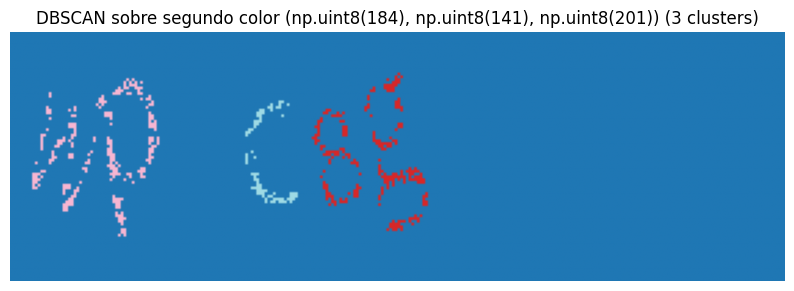

In [101]:
import matplotlib.pyplot as plt

alto, ancho = img_hsv.shape[:2]
canvas = np.zeros((alto, ancho), dtype=np.int32)

for (y, x), label in zip(puntos_muestra, labels):
    canvas[y, x] = label + 1

plt.figure(figsize=(10, 6))
plt.imshow(canvas, cmap="tab20")
plt.title(f"DBSCAN sobre segundo color {segundo_color} ({n_clusters} clusters)")
plt.axis("off")
plt.show()

In [136]:
def calcular_clusters_imagen(imagen):
    i,j,k = imagen.shape
    dicc = {}
    for a in range(i):
        for b in range(j):
            pixel = tuple(imagen[a, b, :])
            dicc[pixel] = dicc.get(pixel,0) + 1
    color_mayor = max(dicc, key=dicc.get)
    top_colores = sorted(dicc.items(), key=lambda item: item[1], reverse=True)
    segundo_color = top_colores[1][0]
    mascara = np.all(imagen == segundo_color, axis=-1)

    puntos = np.argwhere(mascara)

    if len(puntos) > 50000:
        indices = np.random.choice(len(puntos), size=50000, replace=False)
        puntos_muestra = puntos[indices]
    else:
        puntos_muestra = puntos

    db = DBSCAN(eps=15, min_samples=5)
    labels = db.fit_predict(puntos_muestra)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_ruido = list(labels).count(-1)

    alto, ancho = img_hsv.shape[:2]
    canvas = np.zeros((alto, ancho), dtype=np.int32)

    for (y, x), label in zip(puntos_muestra, labels):
        canvas[y, x] = label + 1

    plt.figure(figsize=(10, 6))
    plt.imshow(canvas, cmap="tab20")
    plt.title(f"DBSCAN sobre segundo color {segundo_color} ({n_clusters} clusters)")
    plt.axis("off")
    plt.show()
    return n_clusters

  0%|          | 0/9 [00:00<?, ?it/s]

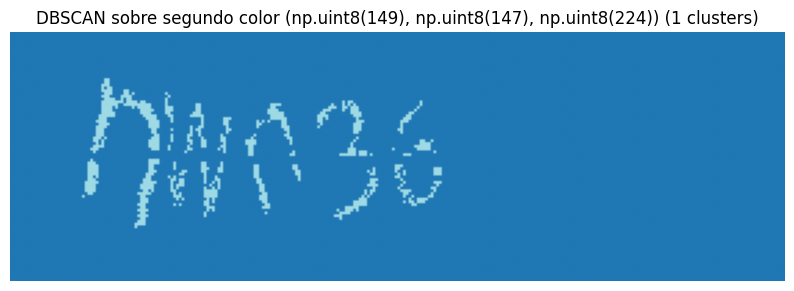

 11%|█         | 1/9 [00:00<00:00,  9.52it/s]

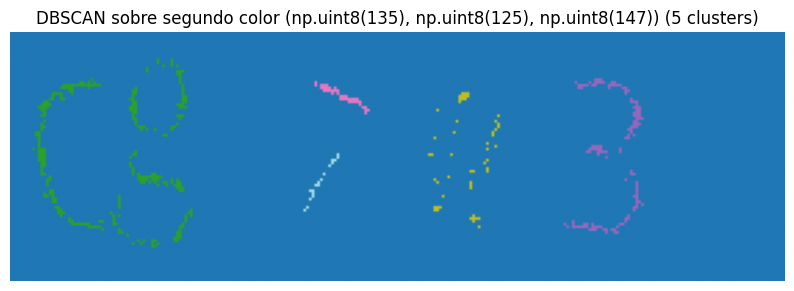

 22%|██▏       | 2/9 [00:00<00:00,  9.29it/s]

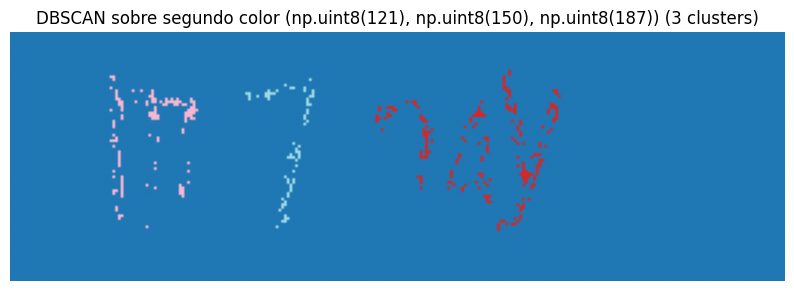

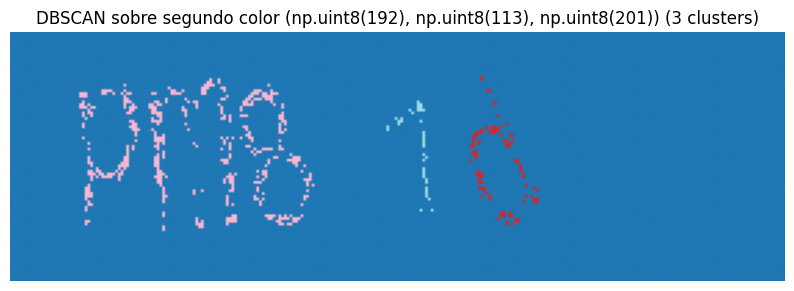

 44%|████▍     | 4/9 [00:00<00:00,  9.91it/s]

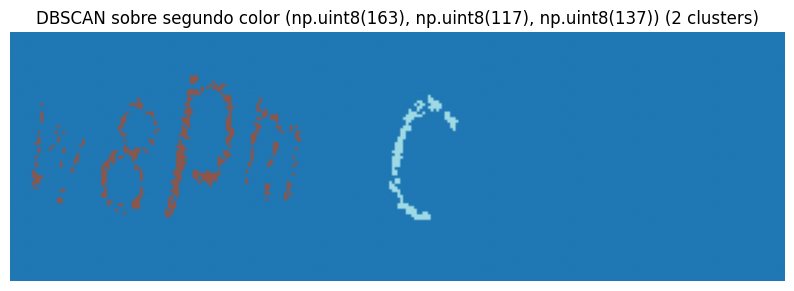

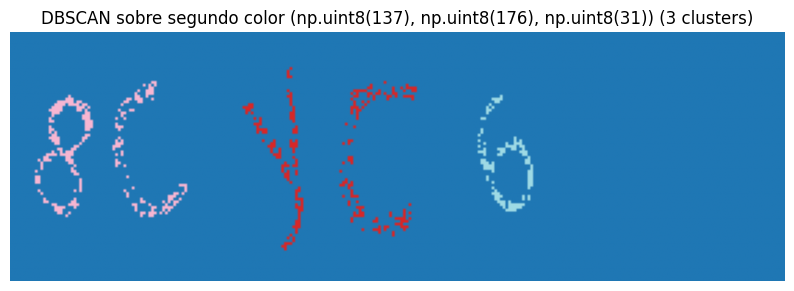

 67%|██████▋   | 6/9 [00:00<00:00,  9.87it/s]

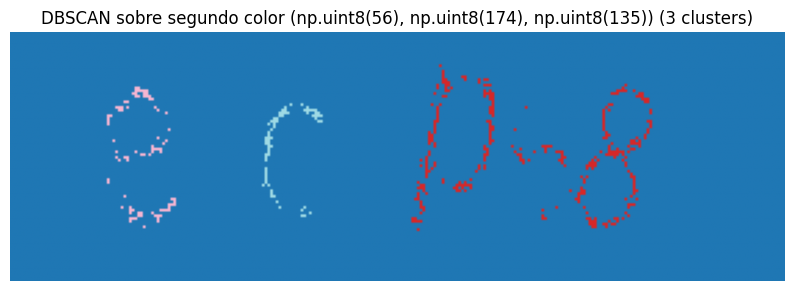

 78%|███████▊  | 7/9 [00:00<00:00,  9.66it/s]

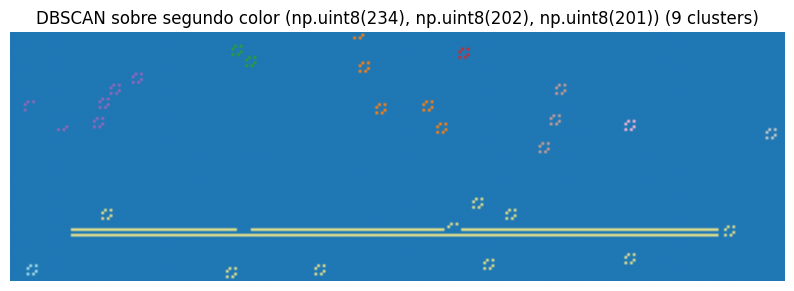

 89%|████████▉ | 8/9 [00:00<00:00,  9.59it/s]

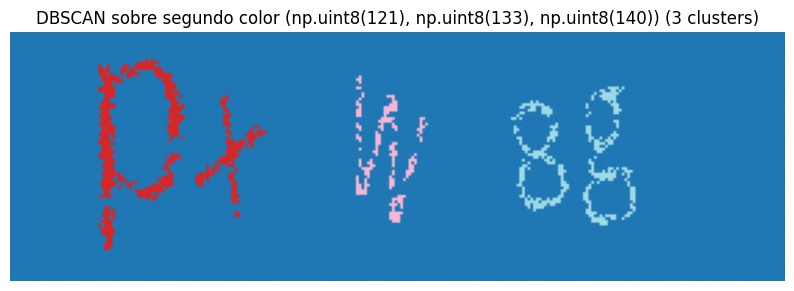

100%|██████████| 9/9 [00:00<00:00,  9.65it/s]


In [137]:
k = max(1, int(len(files) * 0.001))
files_sample = random.sample(files, k)
clusters = [calcular_clusters_imagen(getImage(file)) for file in tqdm(files_sample)]

Como podemos observar en las imagenes resultantes al cruzarse las letras DBSCAN no es capaz de separarlas correctamente.

In [ ]:
import cv2
import numpy as np


def segmentar_digitos_erosion(imagen, kernel_size=3):
    pixels = imagen.reshape(-1, imagen.shape[-1])
    colores, counts = np.unique(pixels, axis=0, return_counts=True)
    segundo_color = tuple(colores[np.argsort(-counts)[1]])
    mascara = np.all(imagen == segundo_color, axis=-1).astype(np.uint8)

    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (kernel_size, kernel_size)
    )
    mascara_erosionada = cv2.erode(mascara, kernel, iterations=1)

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mascara_erosionada
    )

    min_area = 50
    digitos_validos = [
        i for i in range(1, num_labels) if stats[i, cv2.CC_STAT_AREA] >= min_area
    ]

    return len(digitos_validos), labels

  0%|          | 0/99 [00:00<?, ?it/s]

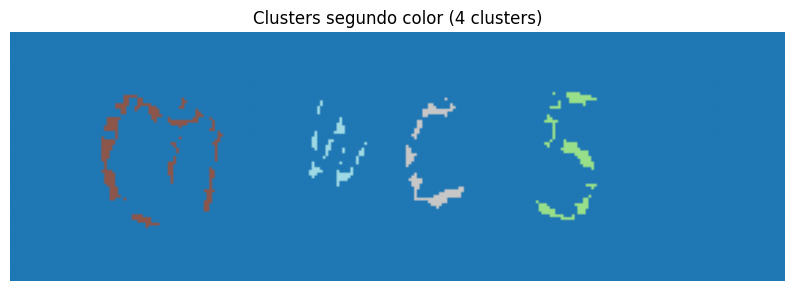

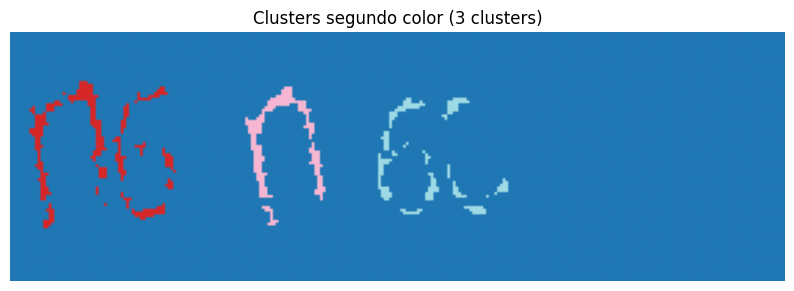

  2%|▏         | 2/99 [00:00<00:09, 10.35it/s]

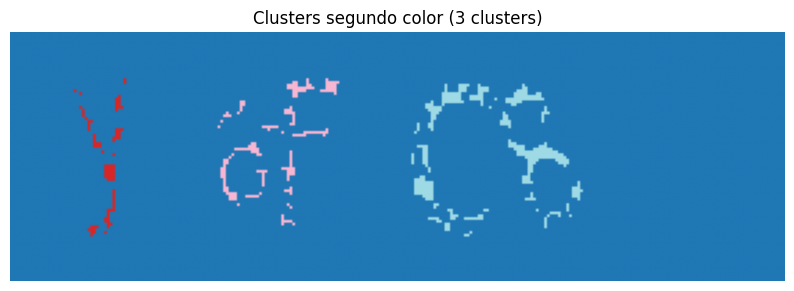

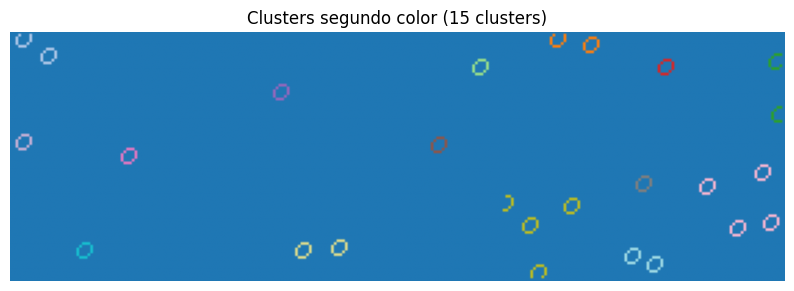

  4%|▍         | 4/99 [00:00<00:08, 10.71it/s]

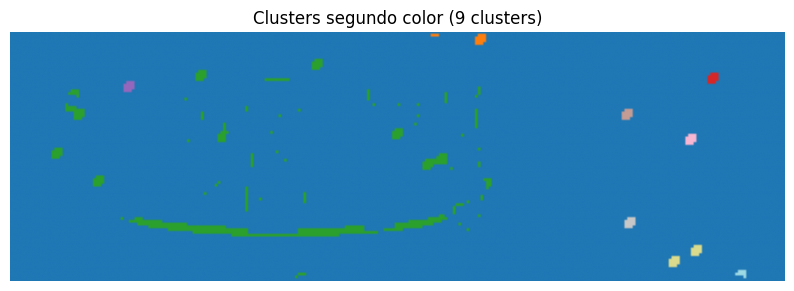

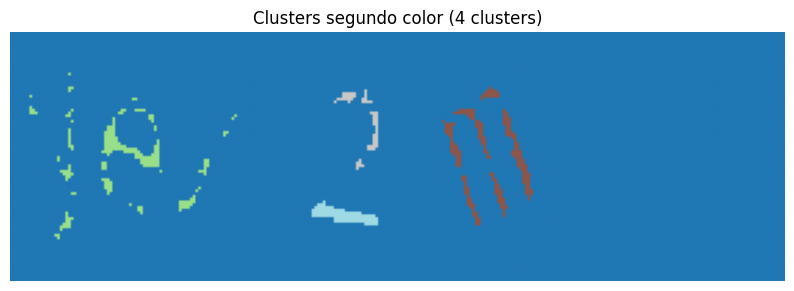

  6%|▌         | 6/99 [00:00<00:08, 10.65it/s]

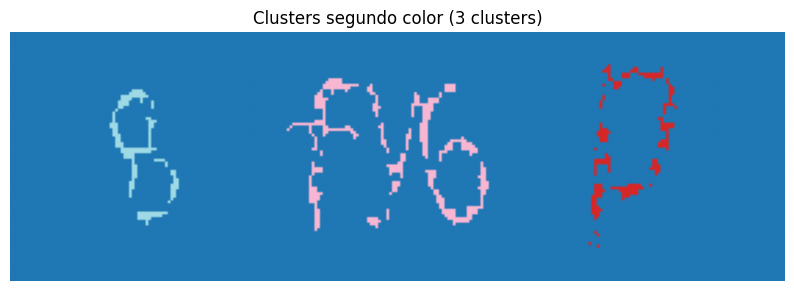

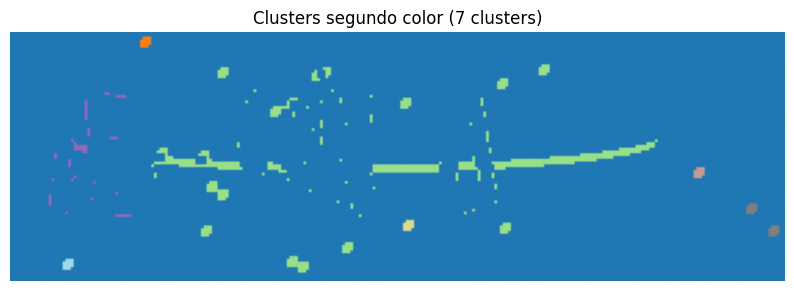

  8%|▊         | 8/99 [00:00<00:08, 10.24it/s]

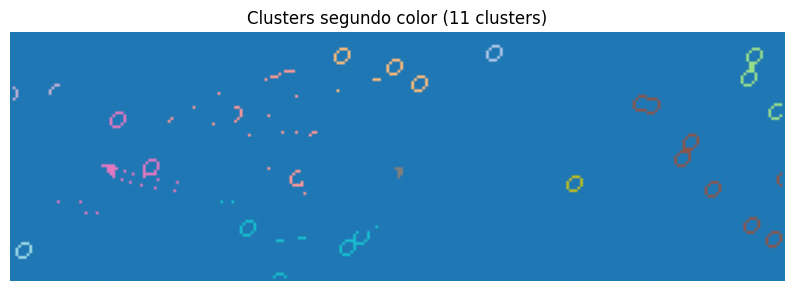

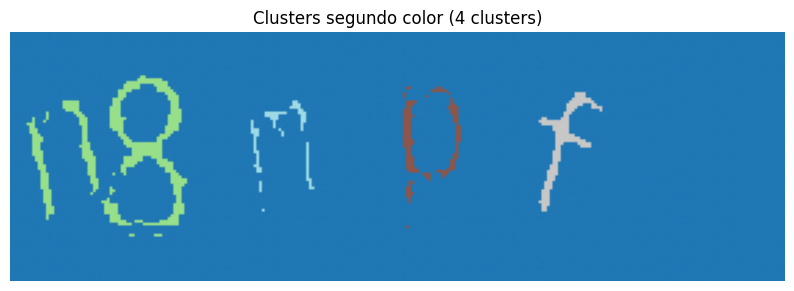

 10%|█         | 10/99 [00:00<00:08, 10.33it/s]

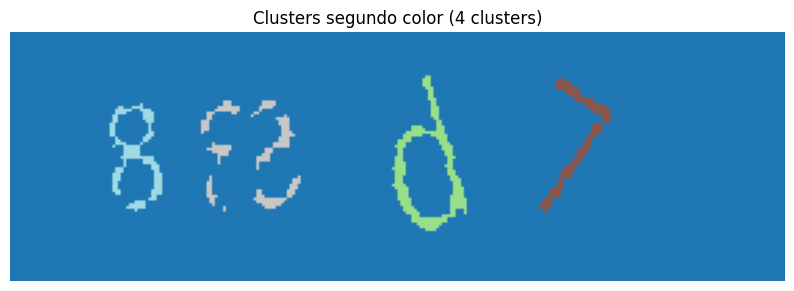

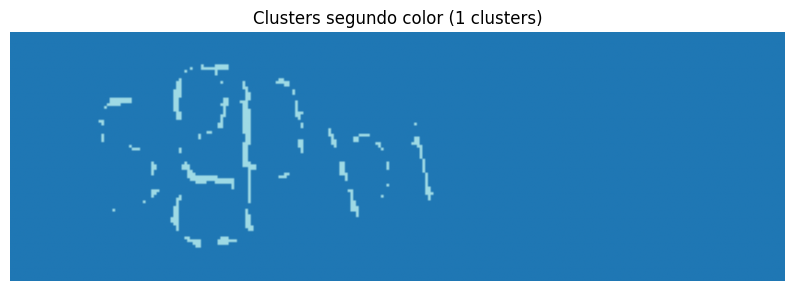

 12%|█▏        | 12/99 [00:01<00:08, 10.25it/s]

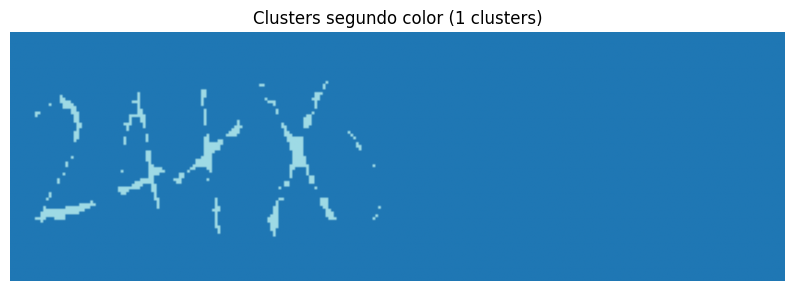

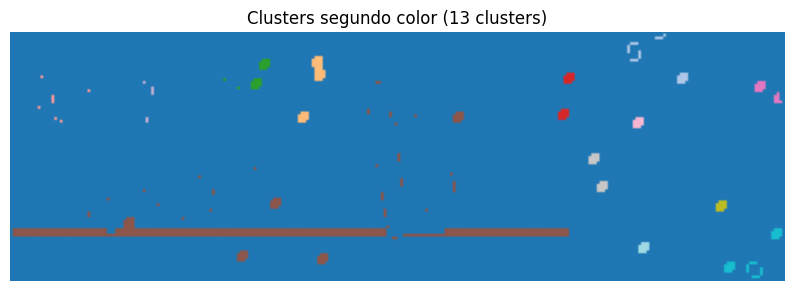

 14%|█▍        | 14/99 [00:01<00:08, 10.35it/s]

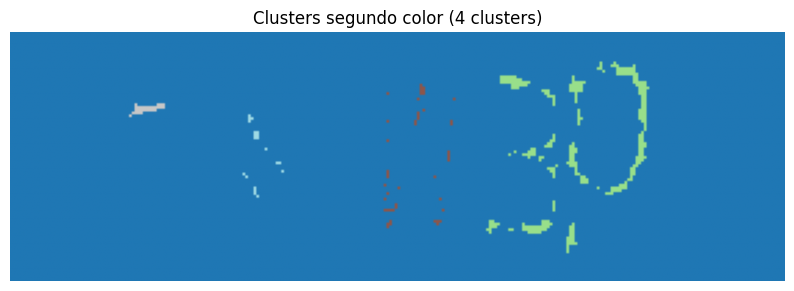

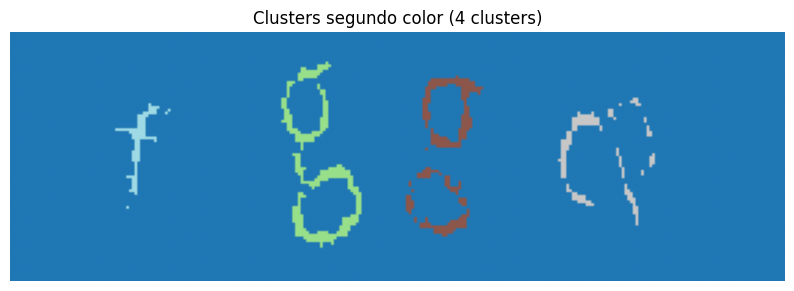

 16%|█▌        | 16/99 [00:01<00:08, 10.24it/s]

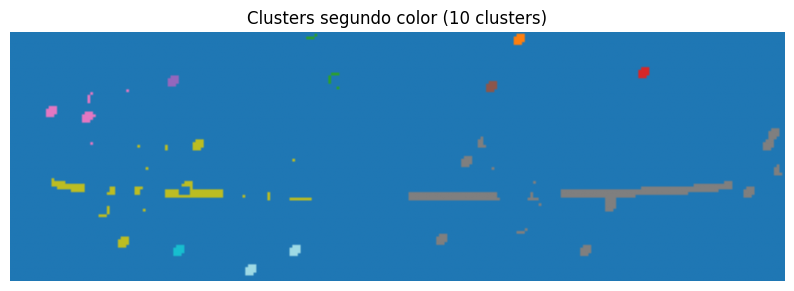

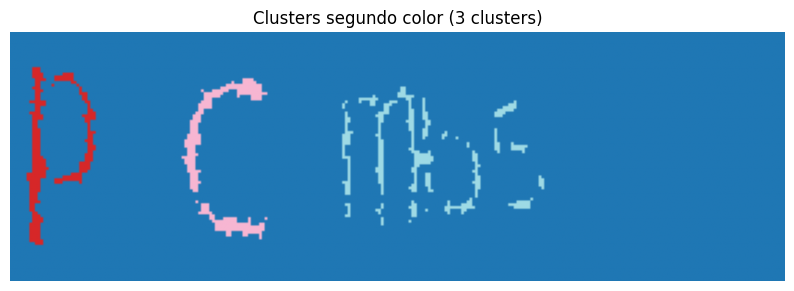

 18%|█▊        | 18/99 [00:01<00:07, 10.34it/s]

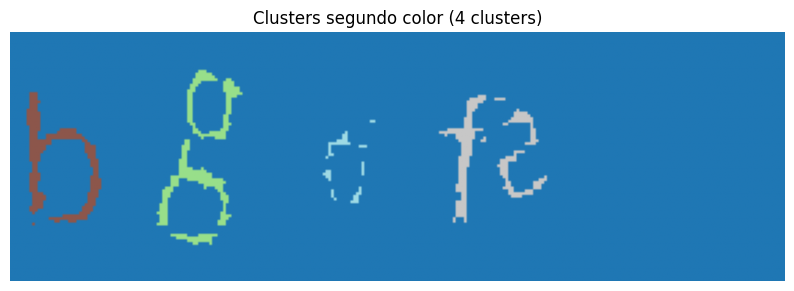

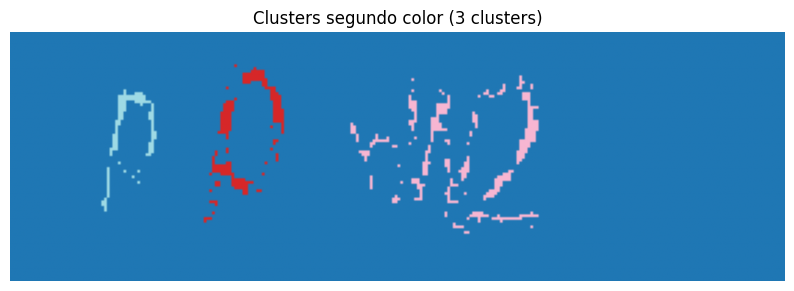

 20%|██        | 20/99 [00:01<00:07, 10.29it/s]

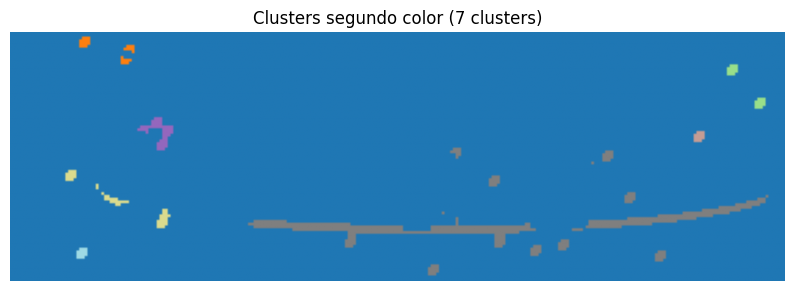

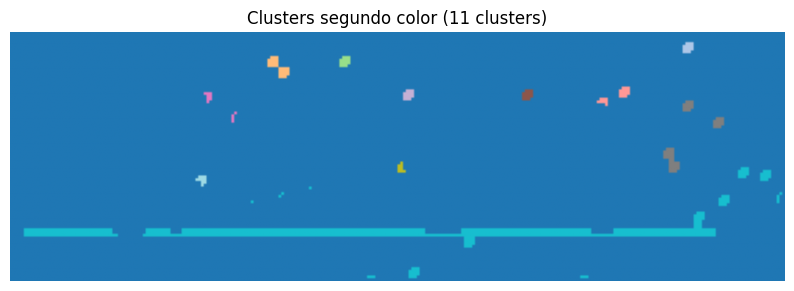

 22%|██▏       | 22/99 [00:02<00:07, 10.35it/s]

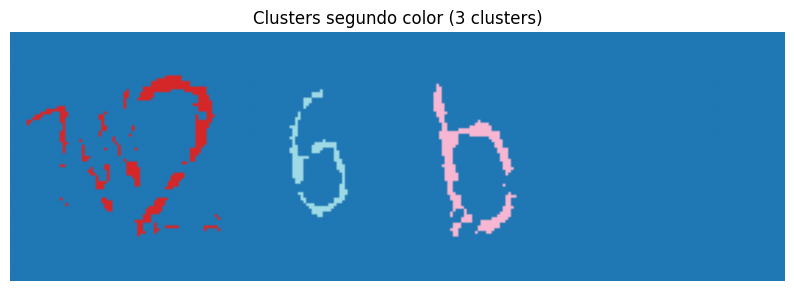

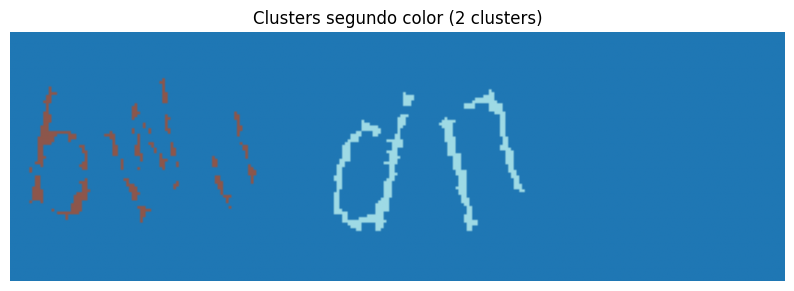

 24%|██▍       | 24/99 [00:02<00:07, 10.20it/s]

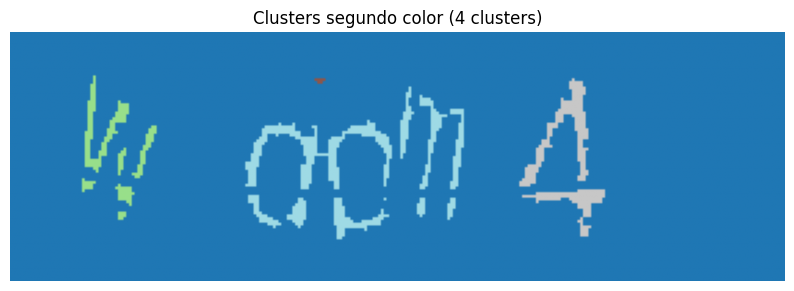

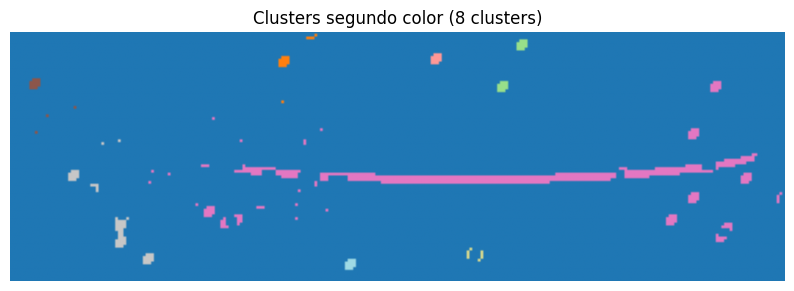

 26%|██▋       | 26/99 [00:02<00:07, 10.22it/s]

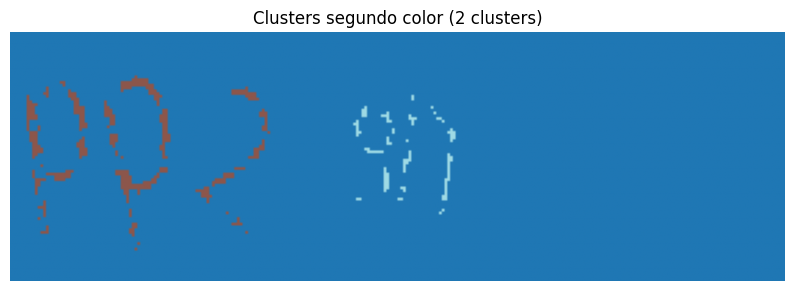

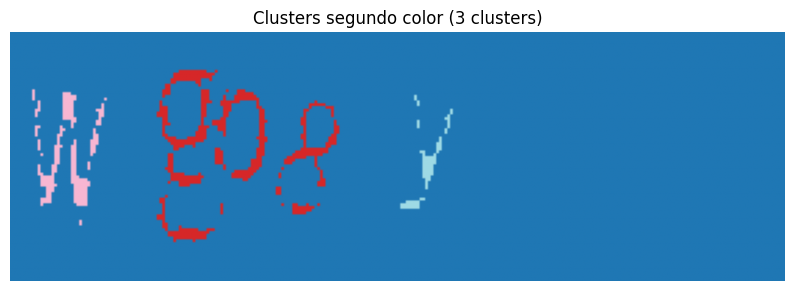

 28%|██▊       | 28/99 [00:02<00:06, 10.23it/s]

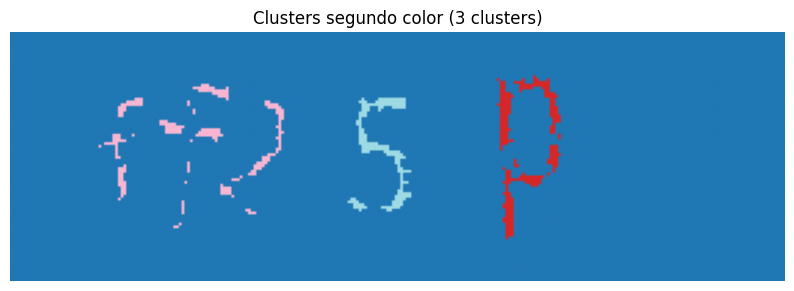

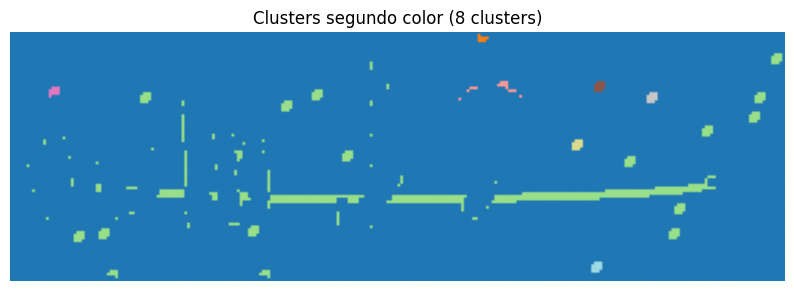

 30%|███       | 30/99 [00:02<00:06, 10.23it/s]

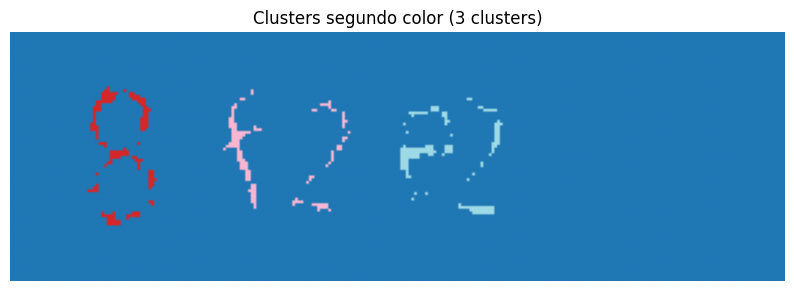

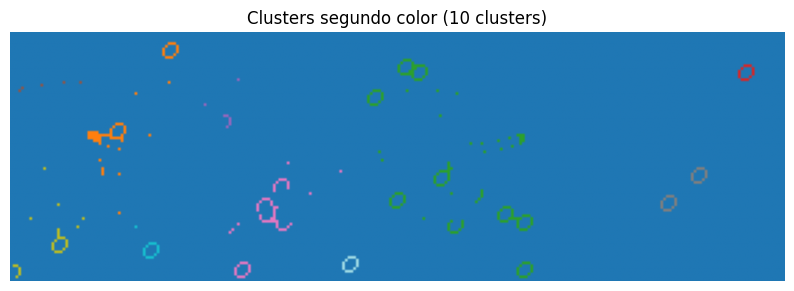

 32%|███▏      | 32/99 [00:03<00:06, 10.38it/s]

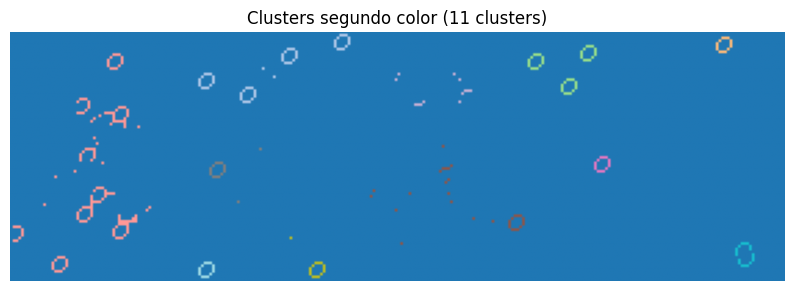

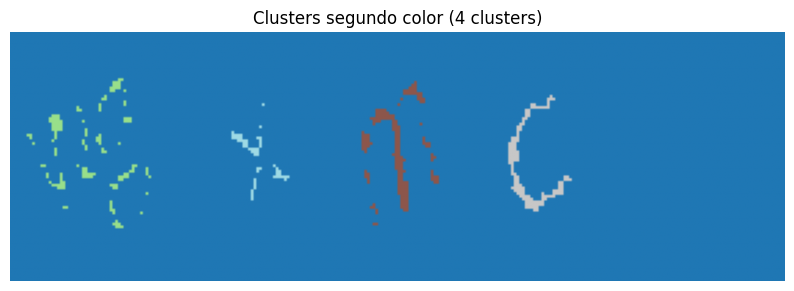

 34%|███▍      | 34/99 [00:03<00:06, 10.47it/s]

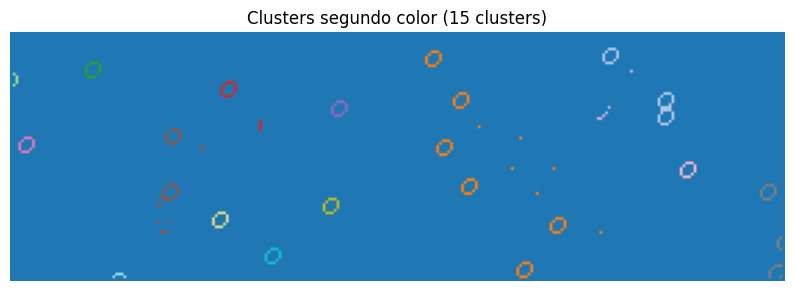

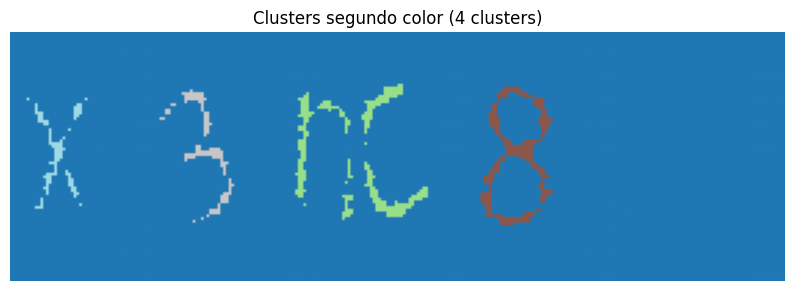

 36%|███▋      | 36/99 [00:03<00:06, 10.16it/s]

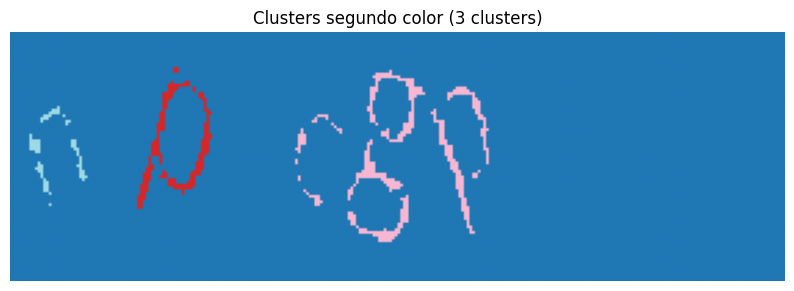

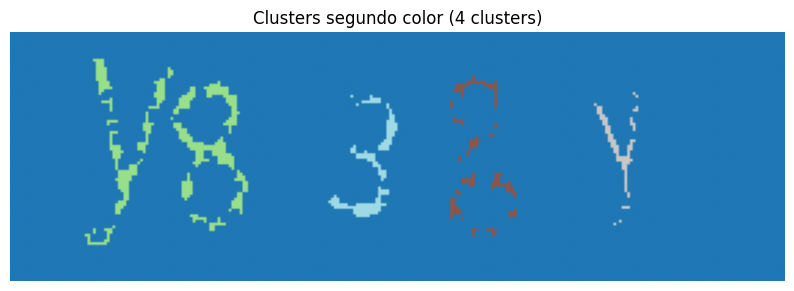

 38%|███▊      | 38/99 [00:03<00:06, 10.12it/s]

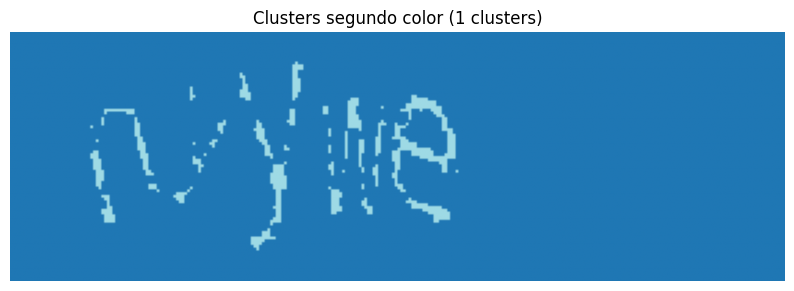

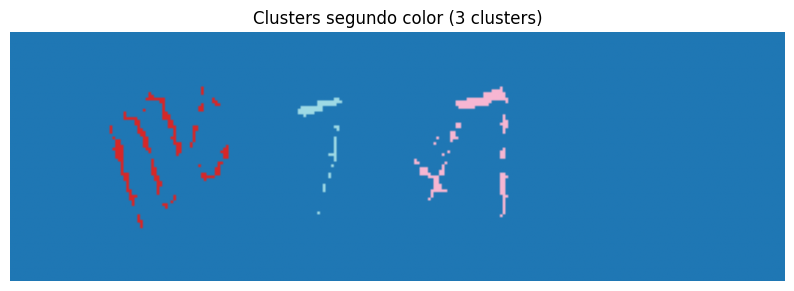

 40%|████      | 40/99 [00:03<00:06,  8.89it/s]

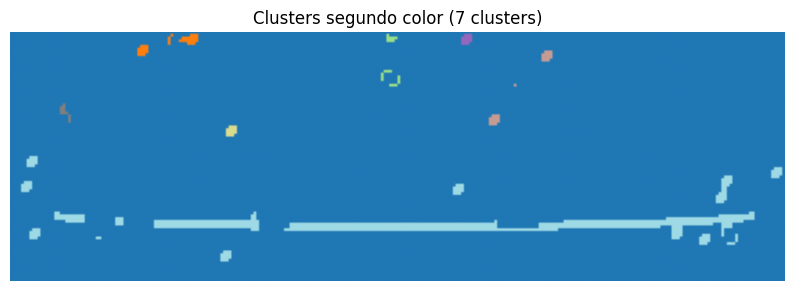

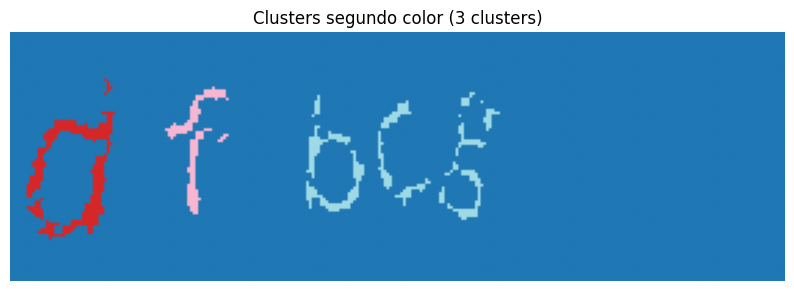

 42%|████▏     | 42/99 [00:04<00:06,  9.17it/s]

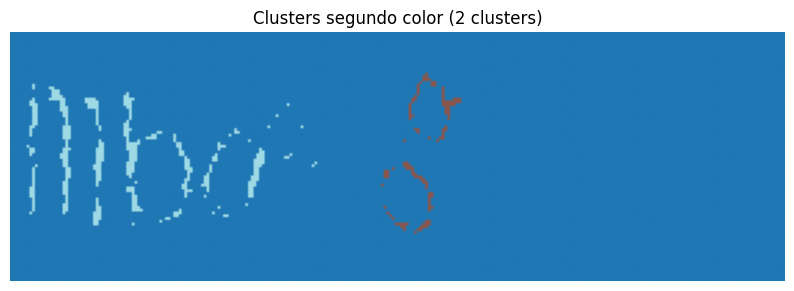

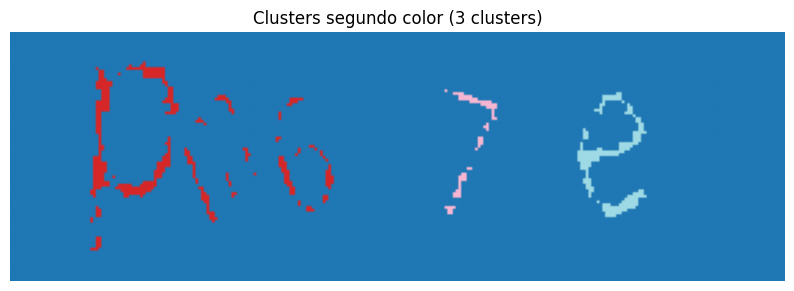

 44%|████▍     | 44/99 [00:04<00:05,  9.62it/s]

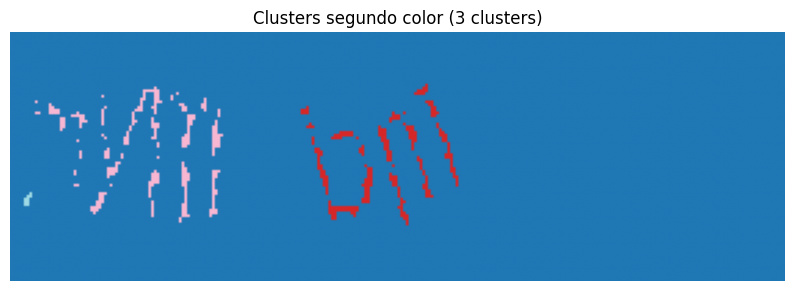

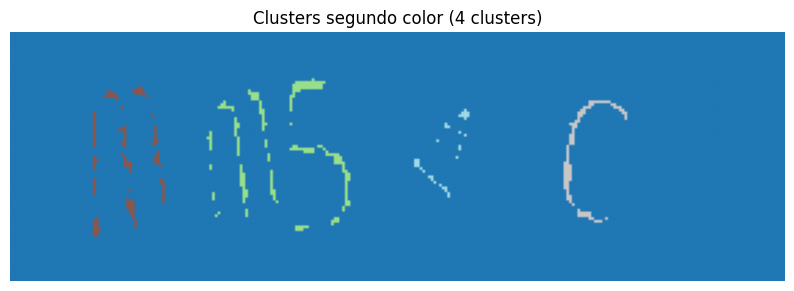

 46%|████▋     | 46/99 [00:04<00:05,  9.98it/s]

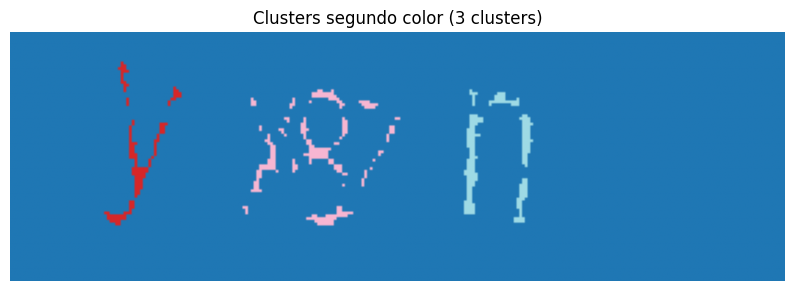

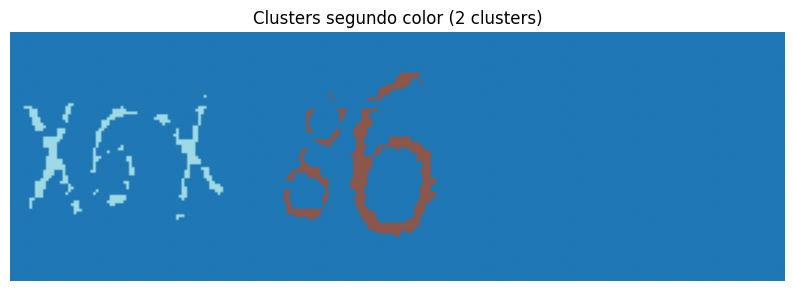

 48%|████▊     | 48/99 [00:04<00:05,  9.90it/s]

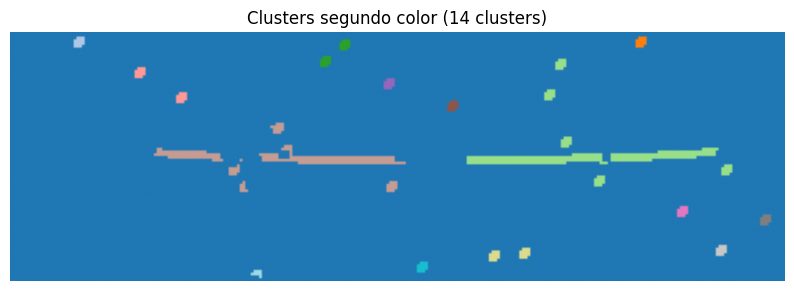

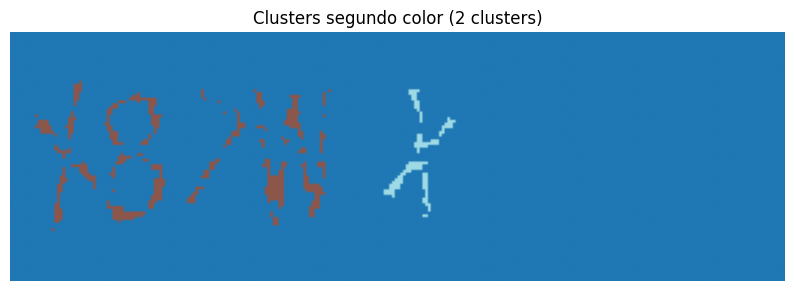

 51%|█████     | 50/99 [00:04<00:04, 10.11it/s]

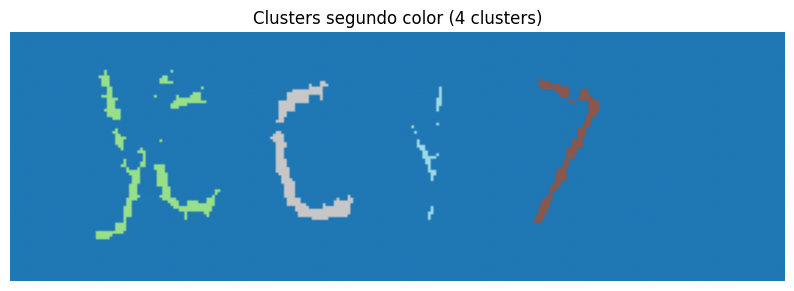

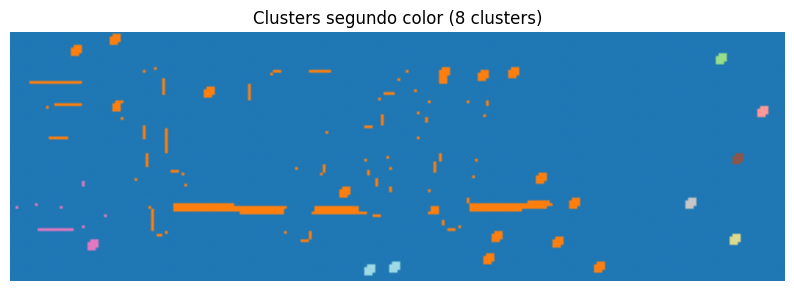

 53%|█████▎    | 52/99 [00:05<00:04, 10.29it/s]

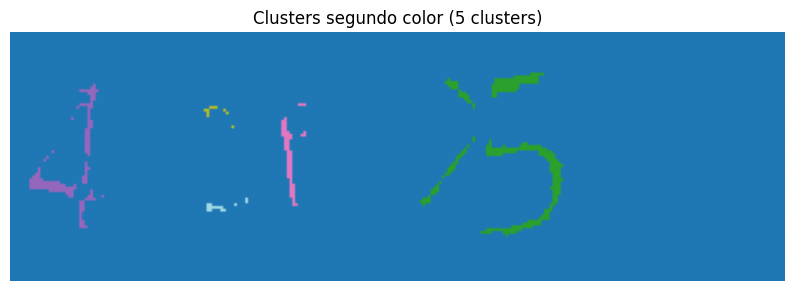

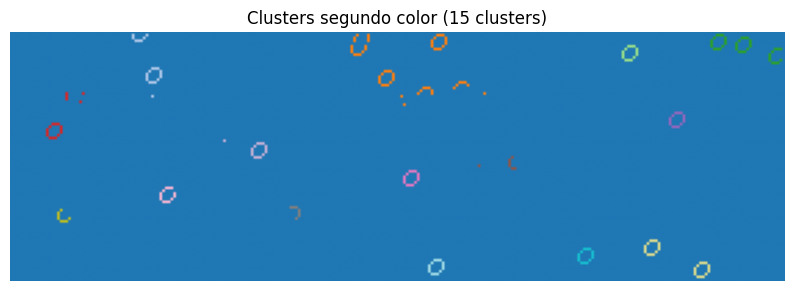

 55%|█████▍    | 54/99 [00:05<00:04, 10.53it/s]

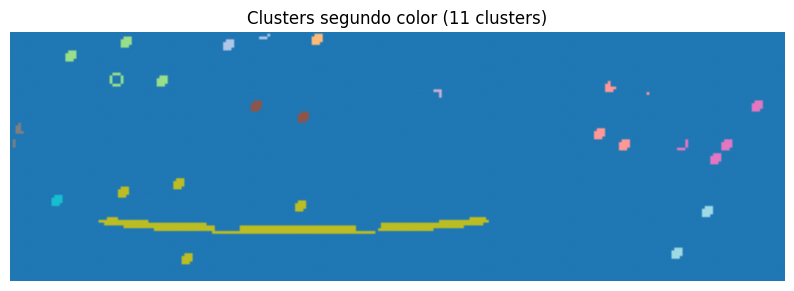

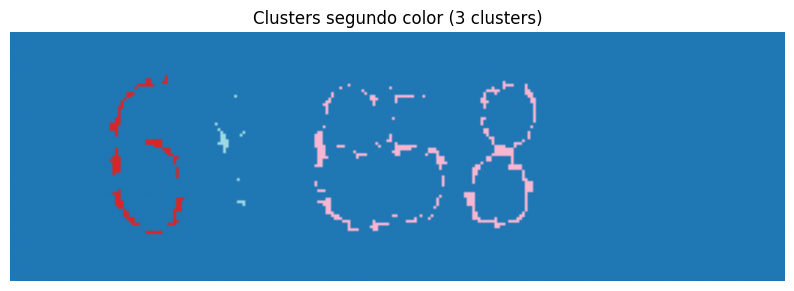

 57%|█████▋    | 56/99 [00:05<00:04, 10.48it/s]

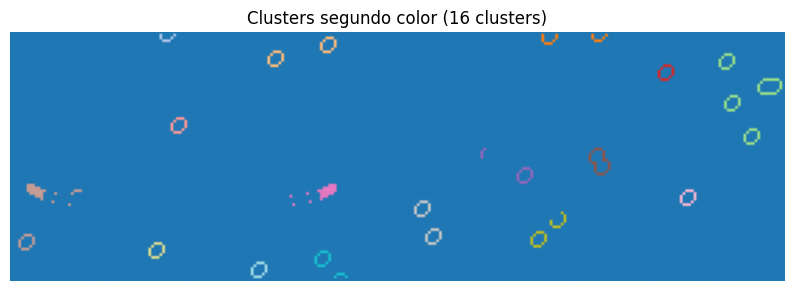

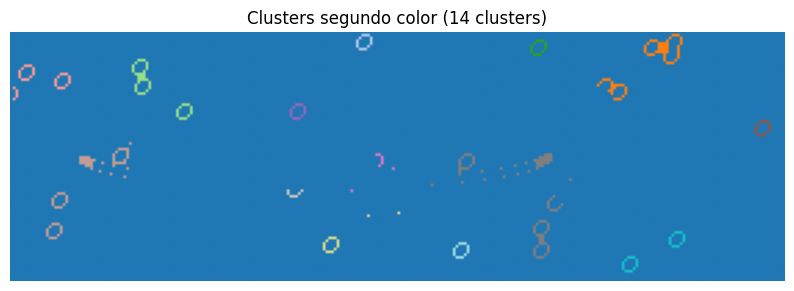

 59%|█████▊    | 58/99 [00:05<00:03, 10.56it/s]

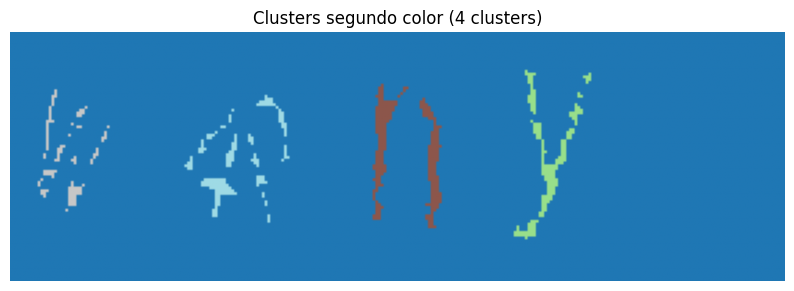

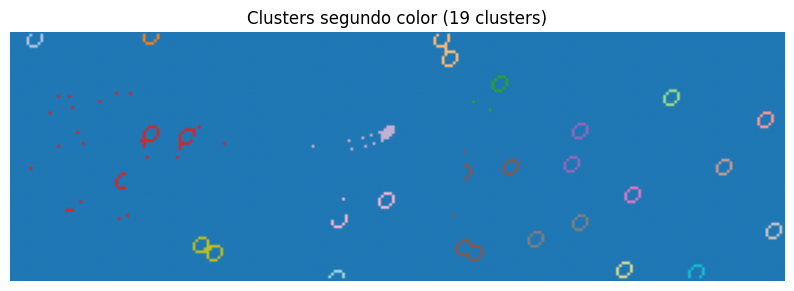

 61%|██████    | 60/99 [00:05<00:03, 10.29it/s]

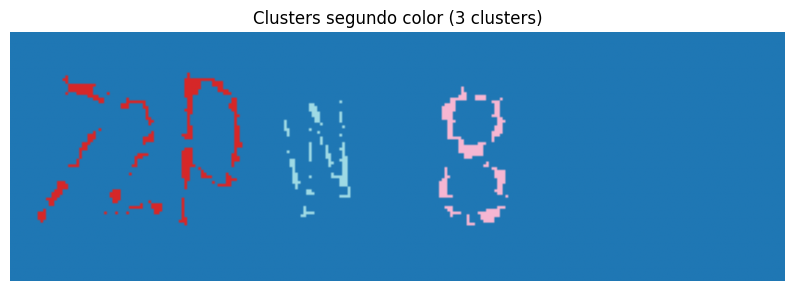

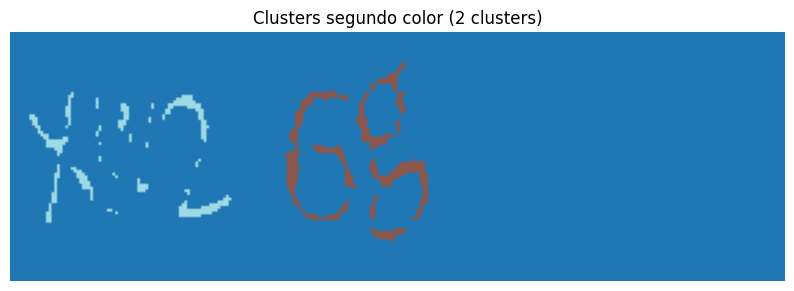

 63%|██████▎   | 62/99 [00:06<00:03, 10.16it/s]

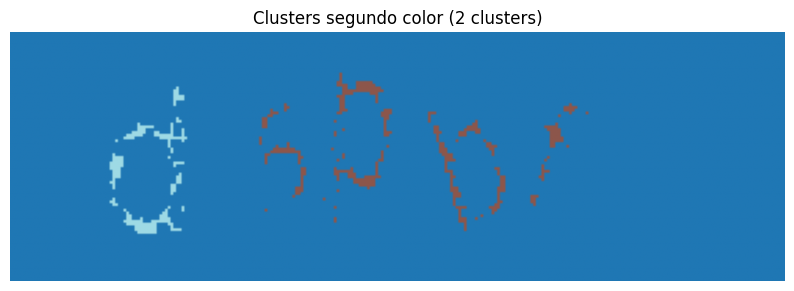

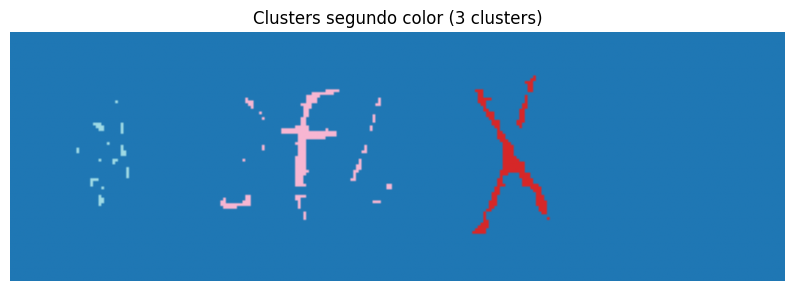

 65%|██████▍   | 64/99 [00:06<00:03, 10.31it/s]

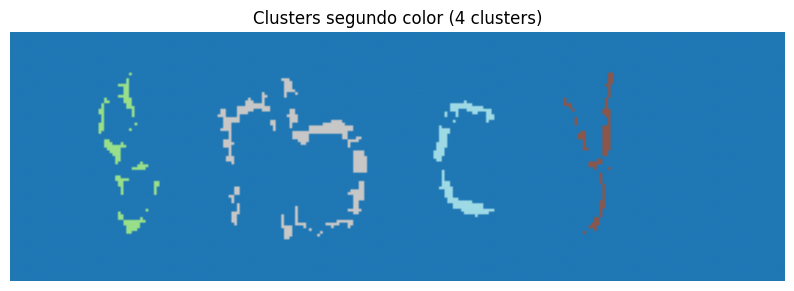

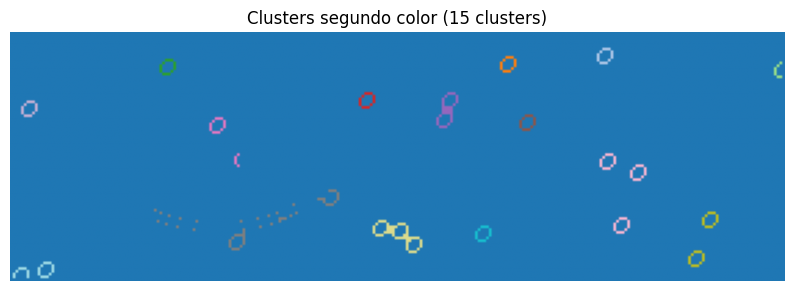

 67%|██████▋   | 66/99 [00:06<00:03, 10.45it/s]

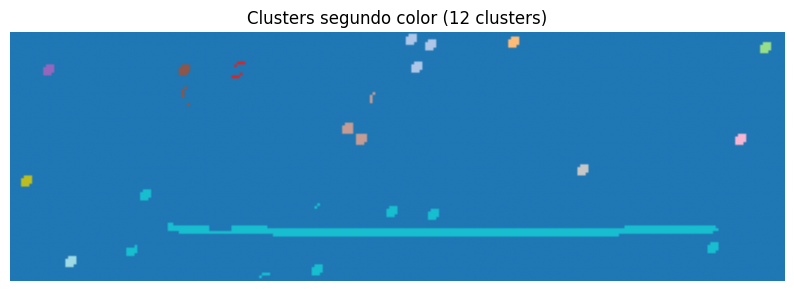

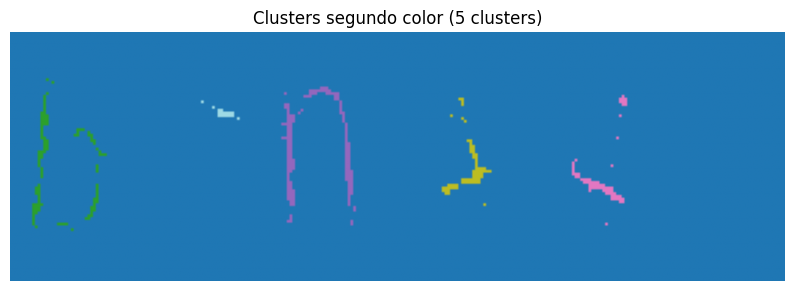

 69%|██████▊   | 68/99 [00:06<00:02, 10.50it/s]

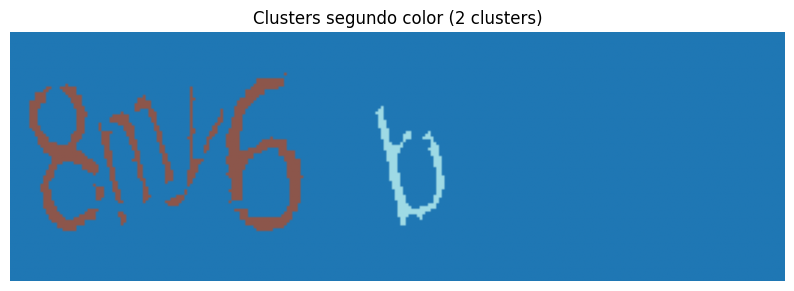

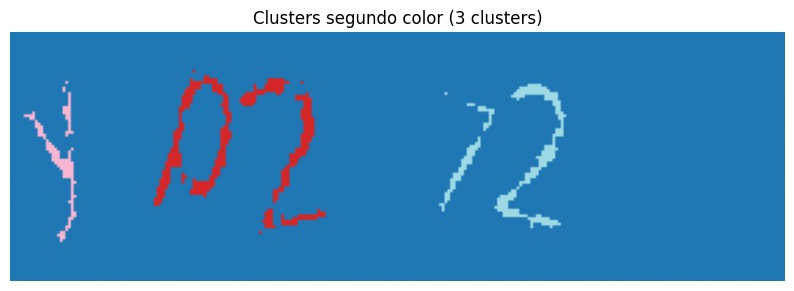

 71%|███████   | 70/99 [00:06<00:02, 10.04it/s]

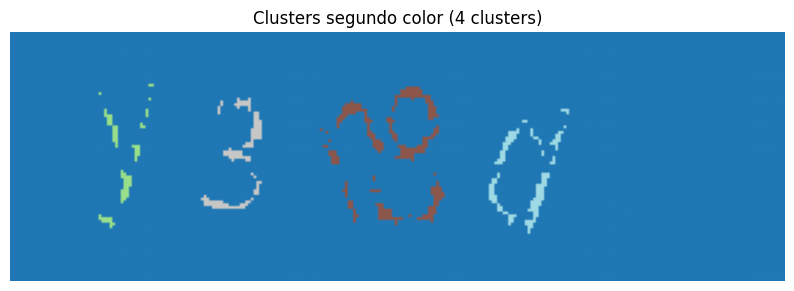

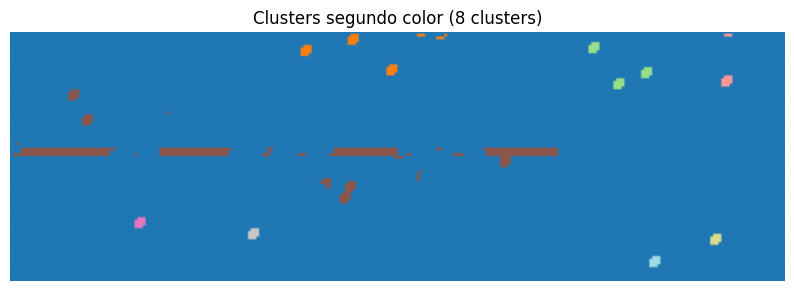

 73%|███████▎  | 72/99 [00:07<00:02, 10.18it/s]

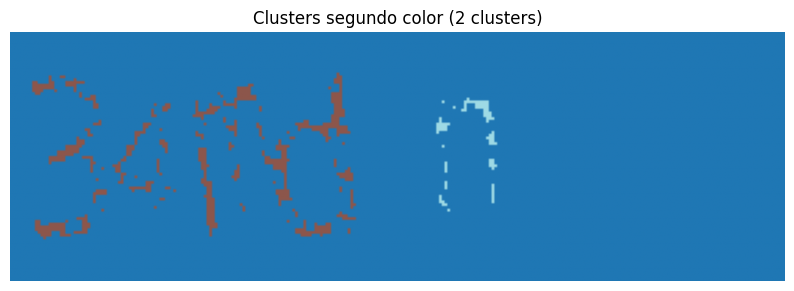

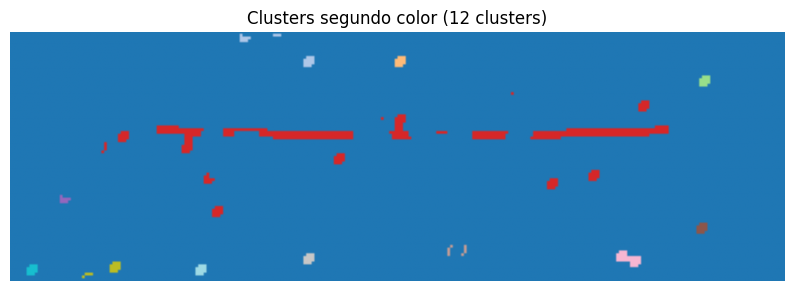

 75%|███████▍  | 74/99 [00:07<00:02, 10.37it/s]

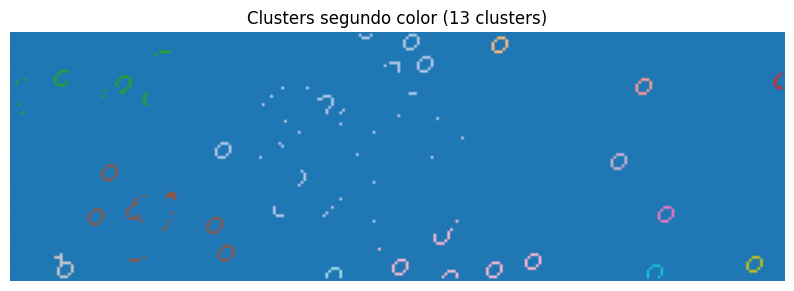

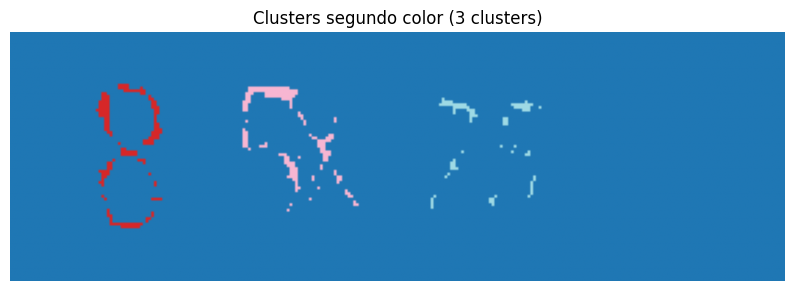

 77%|███████▋  | 76/99 [00:07<00:02, 10.25it/s]

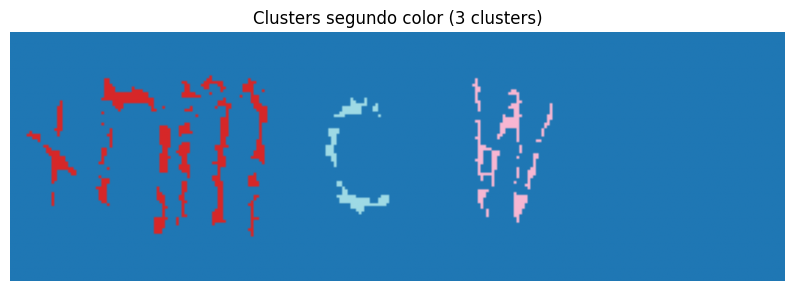

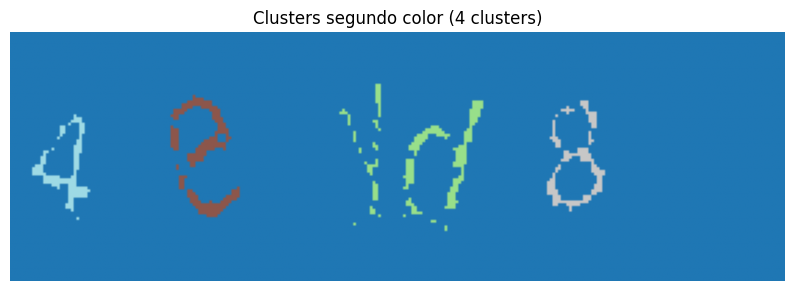

 79%|███████▉  | 78/99 [00:07<00:02, 10.21it/s]

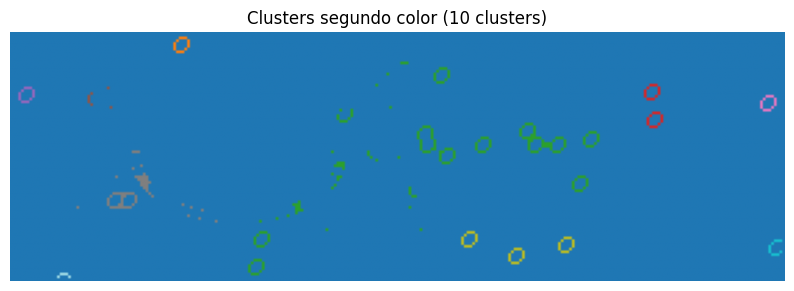

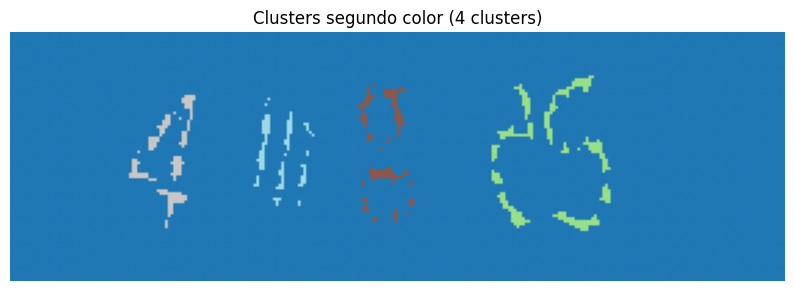

 81%|████████  | 80/99 [00:07<00:01,  9.77it/s]

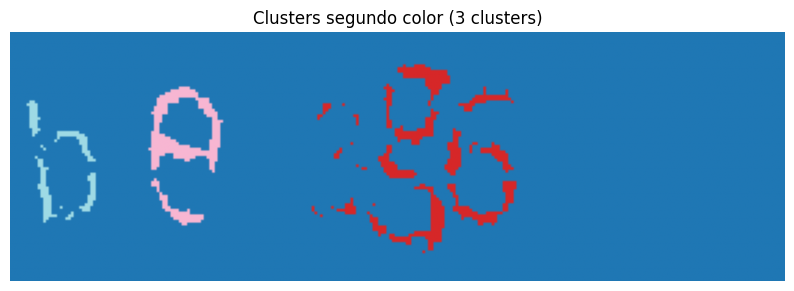

 82%|████████▏ | 81/99 [00:07<00:01,  9.52it/s]

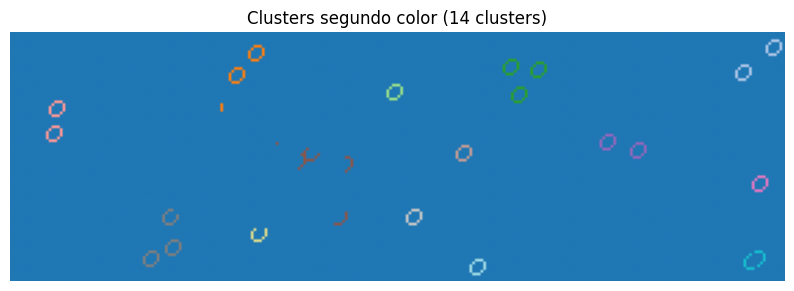

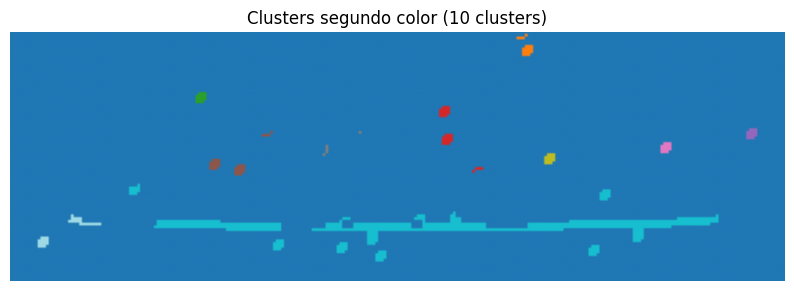

 84%|████████▍ | 83/99 [00:08<00:01,  9.86it/s]

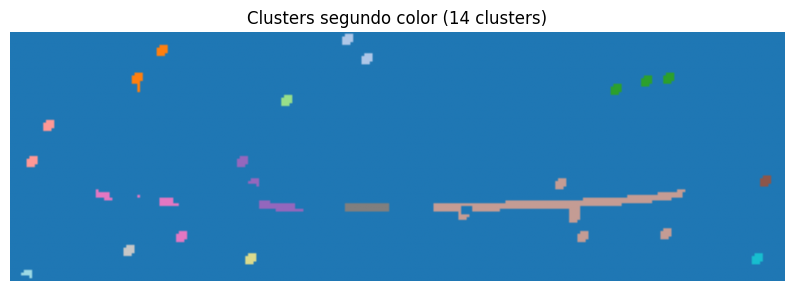

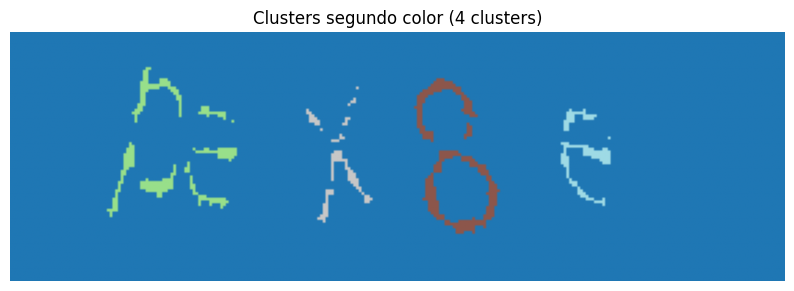

 86%|████████▌ | 85/99 [00:08<00:01, 10.10it/s]

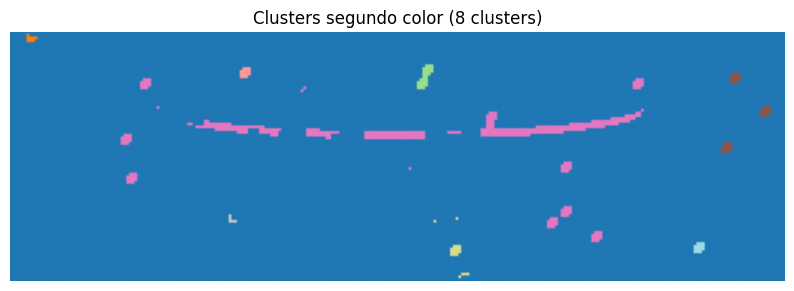

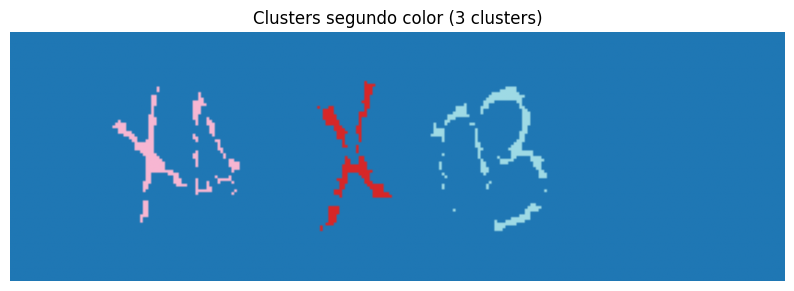

 88%|████████▊ | 87/99 [00:08<00:01, 10.22it/s]

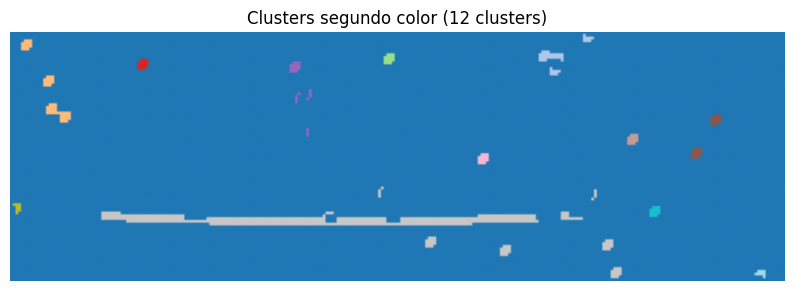

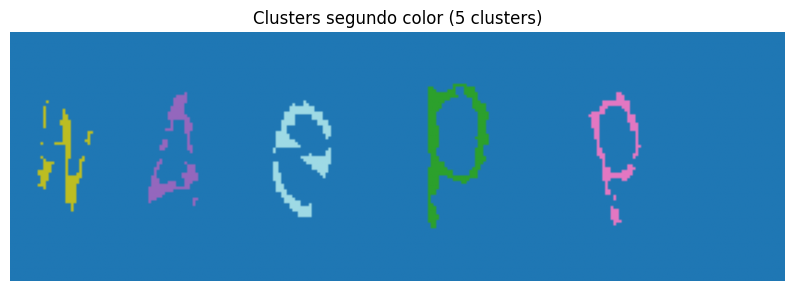

 90%|████████▉ | 89/99 [00:08<00:00, 10.20it/s]

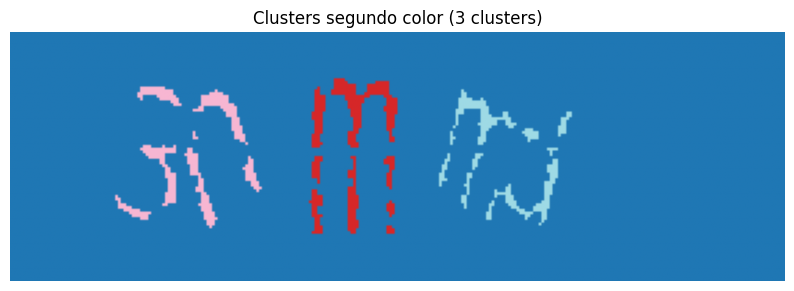

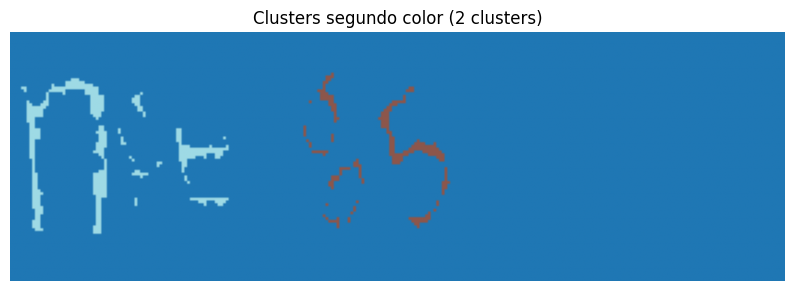

 92%|█████████▏| 91/99 [00:08<00:00, 10.09it/s]

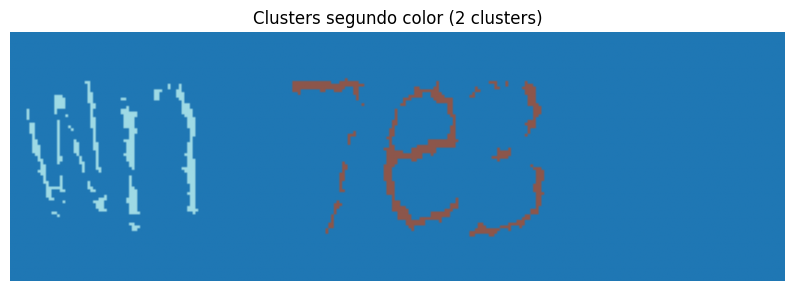

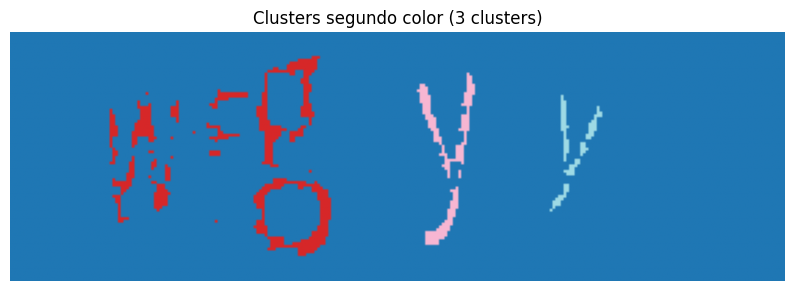

 94%|█████████▍| 93/99 [00:09<00:00, 10.01it/s]

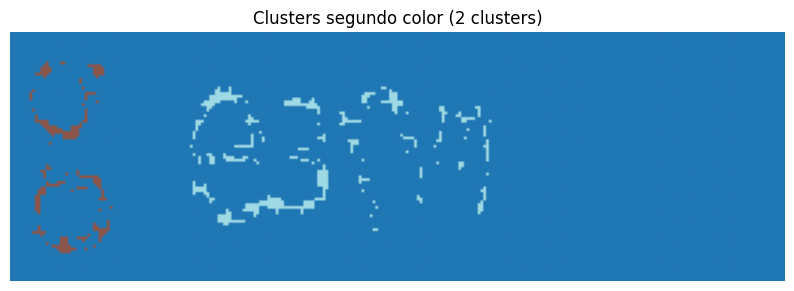

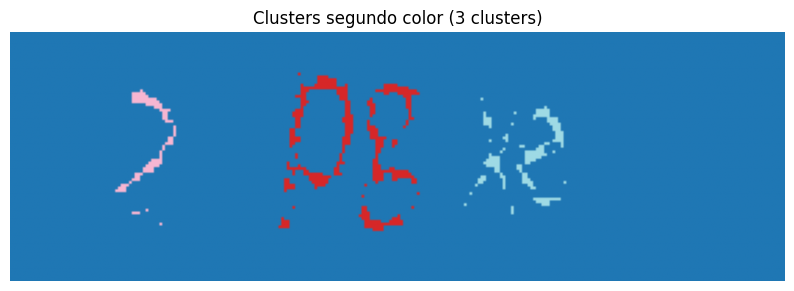

 96%|█████████▌| 95/99 [00:09<00:00, 10.25it/s]

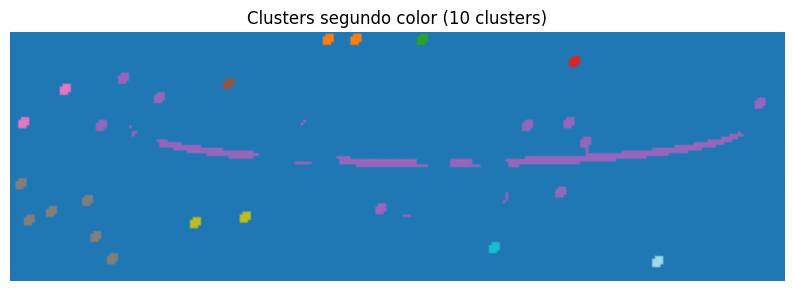

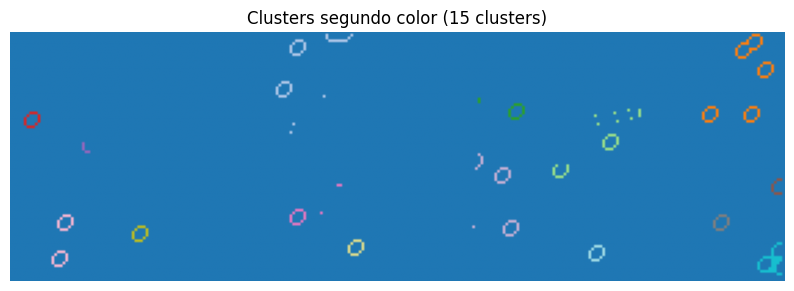

 98%|█████████▊| 97/99 [00:09<00:00, 10.20it/s]

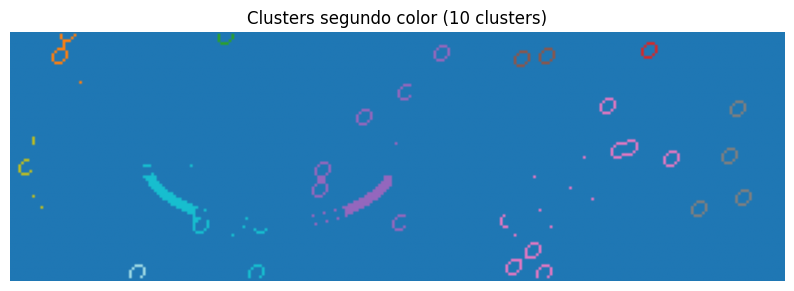

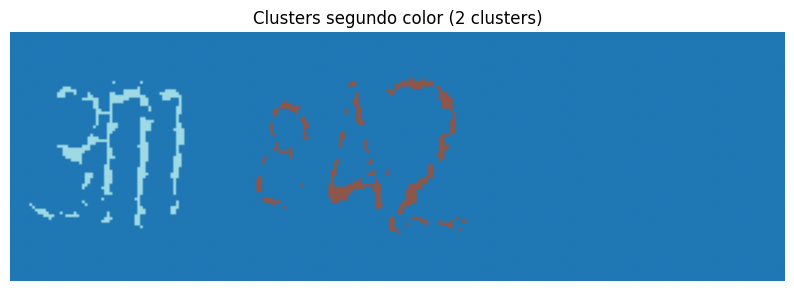

100%|██████████| 99/99 [00:09<00:00, 10.15it/s]


In [125]:
k = max(1, int(len(files) * 0.01))
files_sample = random.sample(files, k)
clusters = [calcular_clusters_imagen(getImage(file)) for file in tqdm(files_sample)]

In [128]:
k = max(1, int(len(files) * 0.01))
files_sample = random.sample(files, k)
clusters = [segmentar_digitos_erosion(getImage(file)) for file in tqdm(files_sample)]

100%|██████████| 99/99 [00:02<00:00, 45.87it/s]


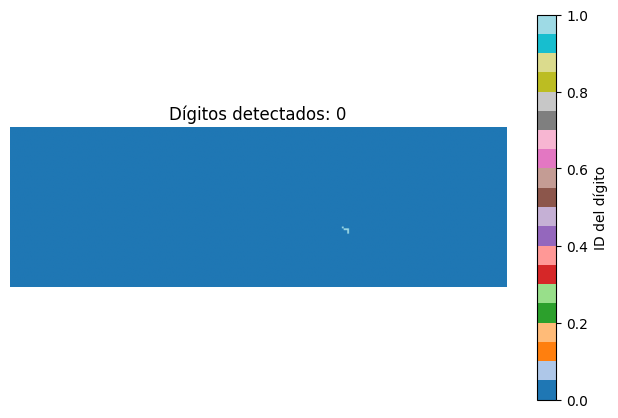

In [ ]:
n_digitos, mapa_clusters = clusters[5]

plt.figure(figsize=(8, 5))
plt.imshow(mapa_clusters, cmap="tab20")
plt.title(f"Dígitos detectados: {n_digitos}")
plt.axis("off")
plt.colorbar(label="ID del dígito")
plt.show()

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

img = Image.open(f"{folder}{files[0]}").convert("L")
img_np = np.array(img)

_, binaria = cv2.threshold(
    img_np, 200, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU
)

kernel_linea = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 3))
sin_linea = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, kernel_linea)

kernel_ruido = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
limpia = cv2.morphologyEx(sin_linea, cv2.MORPH_OPEN, kernel_ruido)

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(limpia)

min_area = 40
cajas = []
for i in range(1, num_labels):
    x, y, w, h, area = stats[i]
    if area >= min_area:
        cajas.append((x, y, w, h))

cajas = sorted(cajas, key=lambda c: c[0])
print(f"Caracteres detectados: {len(cajas)}")

Caracteres detectados: 4
